In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import string
from itertools import product
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from transformers import BertForSequenceClassification, BertTokenizer
import torch
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
from transformers import AdamW
import matplotlib.pyplot as plt

c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Carregar os dados originais
df_nomes = pd.read_csv(r'Bases\nomes_pessoais.csv').drop_duplicates()
df_nomes['y'] = 1
    
df_palavras = pd.read_csv(r'Bases\palavras_comuns.csv').drop_duplicates()
df_palavras['y'] = 0

In [3]:
duplicates = df_palavras[df_palavras['X'].isin(df_nomes['X'].to_list())]
duplicates

,X,y
0,AARAO,0
12,ABADE,0
16,ABADIA,0
17,ABADIAS,0
647,ABAS,0
...,...,...
244672,ZELE,0
244673,ZELEI,0
244686,ZENITE,0
244734,ZERES,0


In [4]:
df_palavras = df_palavras[~df_palavras['X'].isin(df_nomes['X'].to_list())].reset_index(drop=True).sample(n=len(df_nomes), random_state=42)
df = pd.concat([df_nomes, df_palavras])
df.shape

(205122, 2)

In [5]:
duplicates = df_palavras[df_palavras['X'].isin(df_nomes['X'].to_list())]
duplicates

,X,y


In [7]:
# Carregar o arquivo gabarito_formatado.csv
unique_words_df = pd.read_csv(r'Bases\gabarito_formatado.csv')

# Remover valores NaN na coluna 'palavra'
unique_words_df = unique_words_df.dropna(subset=['palavra'])

# Converter todos os valores '-1' para '0' na coluna 'y'
unique_words_df['y'] = unique_words_df['y'].replace(-1, 0)

words_with_negative_label = unique_words_df[unique_words_df['y'] == -1]

words_with_negative_label_list = words_with_negative_label['palavra'].tolist()

print(words_with_negative_label_list)


[]


In [8]:
# Carregar o modelo BERTimbau pré-treinado e o tokenizer
model_name = 'neuralmind/bert-base-portuguese-cased'
bert_model = BertForSequenceClassification.from_pretrained(model_name, num_labels=2)
tokenizer = BertTokenizer.from_pretrained(model_name)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at neuralmind/bert-base-portuguese-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [9]:
# Função para tokenizar os dados
def tokenize_data(data):
    return tokenizer(data, padding=True, truncation=True, return_tensors='pt')

In [10]:
# Tokenizar os dados de treino
X_train_tokens = tokenize_data(df['X'].tolist())
y_train = torch.tensor(df['y'].values)

# Tokenizar as palavras únicas para teste
X_unique_words_tokens = tokenize_data(unique_words_df['palavra'].tolist())
y_true = torch.tensor(unique_words_df['y'].values)

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


In [11]:
# Criar DataLoader para o conjunto de treino
train_dataset = TensorDataset(X_train_tokens['input_ids'], X_train_tokens['attention_mask'], y_train)
train_sampler = RandomSampler(train_dataset)
train_dataloader = DataLoader(train_dataset, sampler=train_sampler, batch_size=16)

# Treinar o modelo BERTimbau
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model.to(device)
optimizer = AdamW(bert_model.parameters(), lr=2e-5)

c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\transformers\optimization.py:591: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


In [12]:
for epoch in range(10):  # Ajuste o número de épocas conforme necessário
    bert_model.train()
    total_loss = 0
    total_correct = 0
    total_samples = 0
    print(f'Época {epoch + 1}/10:')
    for batch_idx, batch in enumerate(train_dataloader):
        optimizer.zero_grad()
        input_ids, attention_mask, labels = batch
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)
        outputs = bert_model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        logits = outputs.logits
        preds = torch.argmax(logits, dim=1)
        total_correct += torch.sum(preds == labels).item()
        total_samples += len(labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

        # Log a cada 10 batches
        if (batch_idx + 1) % 10 == 0:
            avg_loss = total_loss / (batch_idx + 1)
            avg_accuracy = total_correct / total_samples
            print(f'    Batch {batch_idx + 1}/{len(train_dataloader)} - Loss: {avg_loss:.4f}, Acurácia: {avg_accuracy:.4f}')

Época 1/10:
    Batch 10/12821 - Loss: 0.6015, Acurácia: 0.8187
    Batch 20/12821 - Loss: 0.5425, Acurácia: 0.8250
    Batch 30/12821 - Loss: 0.4715, Acurácia: 0.8500
    Batch 40/12821 - Loss: 0.4165, Acurácia: 0.8672
    Batch 50/12821 - Loss: 0.3921, Acurácia: 0.8750
    Batch 60/12821 - Loss: 0.3693, Acurácia: 0.8781
    Batch 70/12821 - Loss: 0.3467, Acurácia: 0.8848
    Batch 80/12821 - Loss: 0.3468, Acurácia: 0.8812
    Batch 90/12821 - Loss: 0.3332, Acurácia: 0.8875
    Batch 100/12821 - Loss: 0.3248, Acurácia: 0.8888
    Batch 110/12821 - Loss: 0.3125, Acurácia: 0.8920
    Batch 120/12821 - Loss: 0.3023, Acurácia: 0.8948
    Batch 130/12821 - Loss: 0.2984, Acurácia: 0.8957
    Batch 140/12821 - Loss: 0.2892, Acurácia: 0.8987
    Batch 150/12821 - Loss: 0.2843, Acurácia: 0.8983
    Batch 160/12821 - Loss: 0.2770, Acurácia: 0.9000
    Batch 170/12821 - Loss: 0.2684, Acurácia: 0.9029
    Batch 180/12821 - Loss: 0.2701, Acurácia: 0.9017
    Batch 190/12821 - Loss: 0.2686, Acuráci

KeyboardInterrupt: 

In [ ]:
# Avaliar o modelo BERTimbau
bert_model.eval()
with torch.no_grad():
    input_ids = X_unique_words_tokens['input_ids'].to(device)
    attention_mask = X_unique_words_tokens['attention_mask'].to(device)
    outputs = bert_model(input_ids, attention_mask=attention_mask)
    logits = outputs.logits
    y_pred = torch.argmax(logits, dim=1).cpu().numpy()

In [ ]:
# Calcular as métricas
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.8749106504646176
Precision: 0.5181128896377422
Recall: 0.8277254374158816
F1 Score: 0.6373056994818652


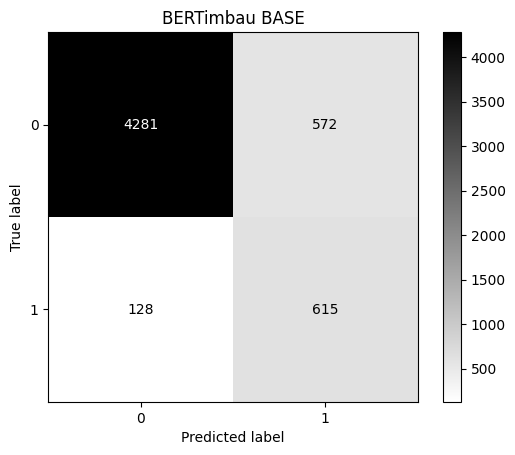

In [ ]:
# Gerar a matriz de confusão
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary')
plt.title('BERTimbau BASE')
plt.show()